# Introduction

This is one part of a two-part project, where the goal is to compare the performance and metrics of two types of network models on the same dataset; Fully Connected Network and Convolutional Neural Network. This notebook covers the Fully Connected Network (FCN) part.

The data used for both of the network models is the CIFAR-10 dataset, which contains 60000 images in total.

> **AI tools were used to help with producing code in this notebook.**

# 1. Business Understanding

The aim of this project is to build a FCN model that classifies 32x32 pixel color images to 10 distinct classes.

### Objectives & Success criteria

The measurable goals of the FCN model are as follows:
- realistic: **test accuracy** of 50% - 55%
- ambitious: **test accuracy** of 57% - 60%

### Evaluation criteria

Along with concrete accuracy scores, we will also be looking at and evaluating the model's learning curves, number of parameters, training time as well as general qualitative analysis on e.g. the model's confusion and misclassified images.

### Plan

In order to reach the set goals, we will first set a baseline for the model after which we will experiment and evaluate it applying one change at a time.

In [6]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

import time
import keras
from keras import layers
from keras.regularizers import l2

import numpy as np
import matplotlib.pyplot as plt

# target accuracies
TARGET_REALISTIC = (0.50, 0.55)
TARGET_AMBITIOUS = (0.57, 0.60)

# random seed for repeatability
RANDOM_SEED = 123
keras.utils.set_random_seed(RANDOM_SEED)

# 2. Data Understanding

The data is fetched from Keras directly. It consists of 60000 32x32 colored images as well as the correct class for each one.

The classes in question are:
- airplane
- automobile
- bird
- cat
- deer
- dog
- frog
- horse
- ship
- truck

We split the dataset into dedicated training and testing sets, with 50000 in the training set and 10000 in the test set.

In [7]:
(x_train_raw, y_train), (x_test_raw, y_test) = keras.datasets.cifar10.load_data()
y_train, y_test = y_train.flatten(), y_test.flatten()

class_names = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

print("Training images: ", x_train_raw.shape, "\nTest images: ", x_test_raw.shape)
print("Pixel range: ", x_train_raw.min(), "-", x_train_raw.max())
print("Images per class: ", np.bincount(y_train))

Training images:  (50000, 32, 32, 3) 
Test images:  (10000, 32, 32, 3)
Pixel range:  0 - 255
Images per class:  [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]


The above shows that each of the 10 classes contains exactly 5000 images in the dataset.

## Example images

In order to see what exactly we are working with, we plot an example image of each class.

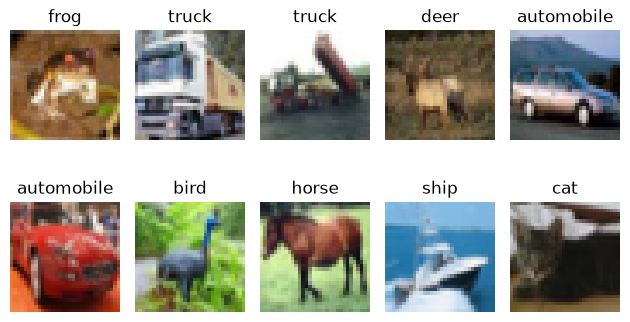

In [8]:
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train_raw[i])
    plt.title(class_names[y_train[i]])
    plt.axis("off")
    plt.tight_layout()
plt.show()

# 3. Data Preparation



The training and test images need to first be converted to `float32` from 8bit integers. This allows us to normalize the values while also making them more memory efficient.

We calculate the mean and standard deviation for each training image for normalization. After normalization, we reshape the images into one dimensional feature vectors. This is required in order for the images to be compatible with the FCN input layer.

In [9]:
x_train_f = x_train_raw.astype("float32")
x_test_f = x_test_raw.astype("float32")

mean = x_train_f.mean(axis=(0,1,2))
std = x_train_f.std(axis=(0,1,2))

x_train = ((x_train_f - mean) / std).reshape(50000, 3072)
x_test = ((x_test_f - mean) / std).reshape(10000, 3072)

# 4. Modeling

After the data has been prepared and the images flattened to a 1D tensor, we proceed to create the baseline model.

We start by creating a model that expects a tensor of shape (3072, ). We set 2 hidden layers, first layer with 1024 units and the other with 512. We use ReLu as the activation function. To help with overfitting we use the dropout technique set to 30%. After training we check what 

In [ ]:
inputs = keras.Input(shape=(3072,))
x = layers.Dense(1024, kernel_regularizer=l2(0.0001), activation="relu")(inputs)
x = layers.Dense(512, kernel_regularizer=l2(0.0001), activation="relu")(x)
outputs = layers.Dense(10, activation="softmax")(x)

model = keras.Model(inputs=inputs, outputs=outputs, name="cifar10_fcn")

In [11]:
model.summary()

Model: "cifar10_fcn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │     3,146,752 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,676,682 (14.03 MB)

 Trainable params: 3,676,682 (14.03 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
model.compile(
    loss=keras.losses.SparseCategoricalCrossentropy(),
    optimizer=keras.optimizers.Adam(),
    metrics=["accuracy"],
)

In [13]:
t0 = time.time()
history = model.fit(
    x_train, y_train,
    batch_size=64,
    epochs=20,
    validation_split=0.2,
)
print("Training time: ", round(time.time() - t0, 1), " seconds")

Epoch 1/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.3217 - loss: 3.3225 - val_accuracy: 0.3719 - val_loss: 2.1024
Epoch 2/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.3557 - loss: 2.0699 - val_accuracy: 0.3834 - val_loss: 1.9637
Epoch 3/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.3499 - loss: 2.0566 - val_accuracy: 0.3759 - val_loss: 1.9981
Epoch 4/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.3501 - loss: 2.0645 - val_accuracy: 0.3852 - val_loss: 2.0115
Epoch 5/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.3512 - loss: 2.0683 - val_accuracy: 0.3728 - val_loss: 2.0119
Epoch 6/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.3494 - loss: 2.0751 - val_accuracy: 0.3657 - val_loss: 2.0388
Epoch 7/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.3480 - loss: 2.0817 - val_accuracy: 0.3707 - val_loss: 2.0120
Epoch 8/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.3489 - loss: 2.0785 - val_accuracy: 

# 5. Evaluation

todo

## Learning curves

todo

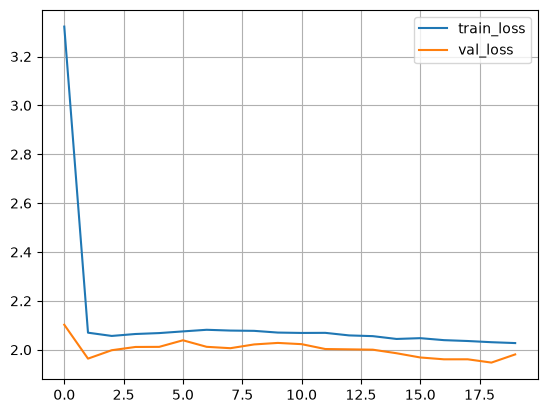

In [14]:
plt.plot(history.history["loss"], label="train_loss")
plt.plot(history.history["val_loss"], label="val_loss")
plt.legend()
plt.grid()
plt.show()

## Test accuracy

In [15]:
test_scores = model.evaluate(x_test, y_test, verbose=2)

print("Test loss: ", test_scores[0])
print("Test accuracy: ", test_scores[1])

313/313 - 0s - 2ms/step - accuracy: 0.3907 - loss: 1.9660
Test loss:  1.965964674949646
Test accuracy:  0.39070001244544983


## Results grid

| Run | Regularization | Reg. settings | Hidden layers | Optimizer | Batch size | Epochs | Test acc. | Time (s) |
|---|---|---|---|---|---|---|---|---|
| 1 | Dropout | rate 0.3, after each hidden layer | 1024, 512 | Adam | 64 | 20 | **0.4977** | 365.3 |
| 2 | | | | | | | | |
| 3 | | | | | | | | |
| 4 | | | | | | | | |
| 5 | | | | | | | | |


## Probability distributions

todo

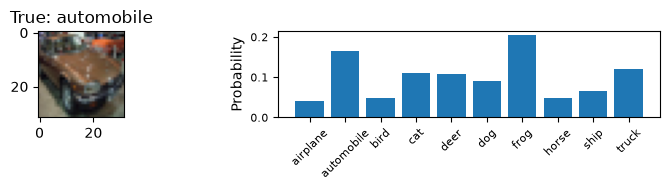

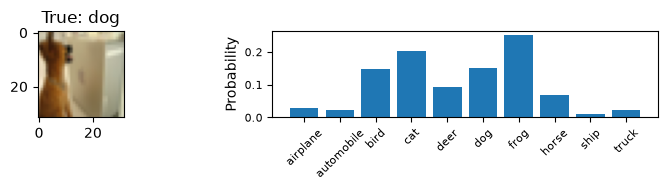

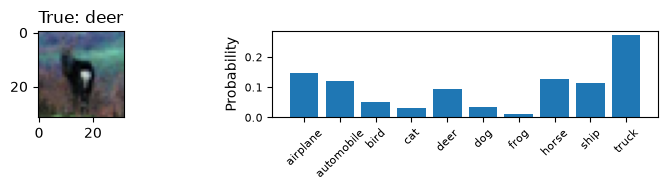

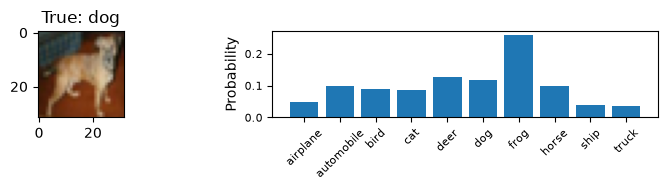

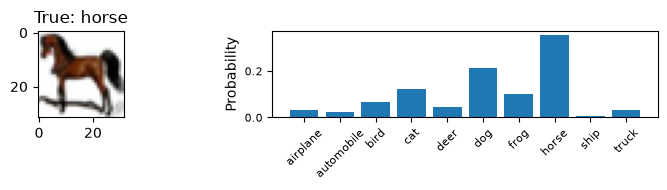

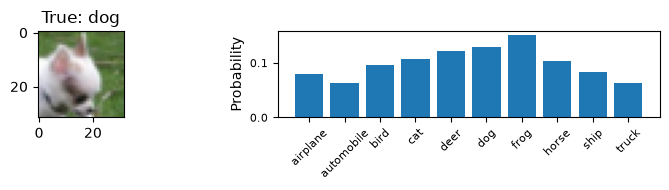

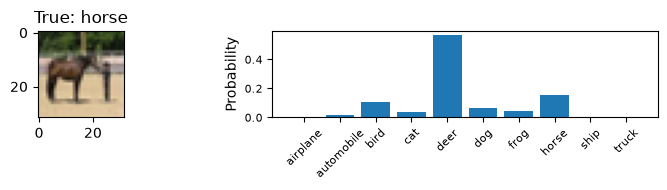

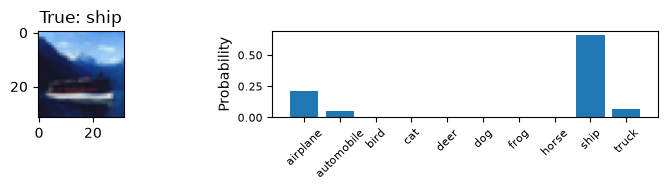

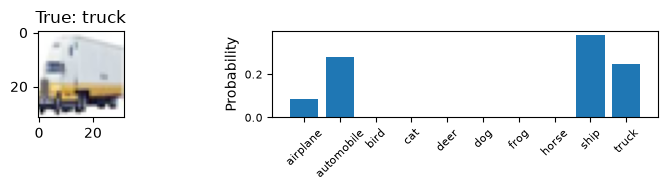

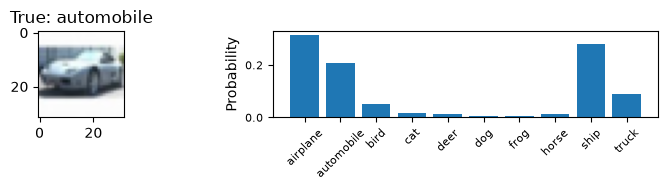

In [16]:
def to_img(x_flat):
    img = x_flat.reshape(32, 32, 3) * std + mean
    return np.clip(img / 255, 0, 1)

y = model(x_test)
start = 2000

for k in range(10):
    plt.figure(figsize=(8, 2))
    plt.subplot(1, 2, 1)
    plt.imshow(to_img(x_test[start + k]))
    plt.title("True: " + class_names[y_test[start+k]], fontsize=12)
    plt.subplot(1, 2, 2)
    plt.bar(np.arange(10), y[start+k].numpy().flatten())
    plt.xticks(range(10), class_names, rotation=45, fontsize=8)
    plt.yticks(fontsize=8)
    plt.ylabel("Probability", fontsize=10)
    plt.tight_layout()

## Misclassified images

todo

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Missclassified:  6093 / 10000


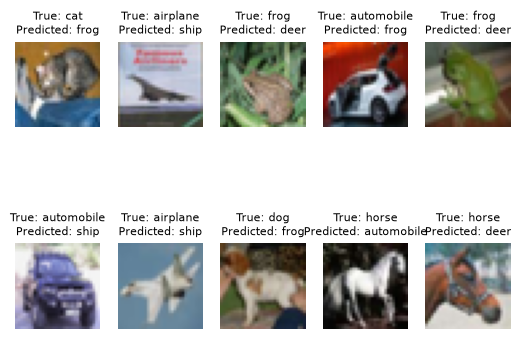

In [17]:
y_pred = np.argmax(model.predict(x_test), axis=1)
wrong = np.where(y_pred != y_test)[0]

print("Missclassified: ", len(wrong), "/", len(y_test))

for k in range(10):
    i = wrong[k]
    plt.subplot(2, 5, k+1)
    plt.imshow(to_img(x_test[i]))
    plt.title(f"True: {class_names[y_test[i]]}\nPredicted: {class_names[y_pred[i]]}", fontsize=8)
    plt.axis("off")
plt.show()